# Experiment 3
## Agent Architectures - The BDI Deliberation Cycle

**Aim:** Implement a Belief–Desire–Intention (BDI) agent on a 15×15 Tileworld, measure how the commitment strategy (parameterised by γ) affects performance as world dynamism increases.

## Theory

A BDI agent has three attitudes:
- **Beliefs (B):** what the agent takes to be true, revised from percepts.
- **Desires (D):** candidate goals (holes to fill) — options, not commitments.
- **Intentions (I):** the desire committed to and being pursued.

Four BDI functions: `brf`, `options`, `filter`, `plan`.

**Commitment (parameterised by γ — actions between re-deliberations):**
- γ = 1 → cautious: re-deliberates after every action  
- γ → ∞ → bold: never reconsiders until intention achieved/impossible  
- **Single-minded**: drops intention once believed unachievable

In [1]:
import random
import heapq
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# ─────────────────────────────────────────────
# Tileworld Environment
# ─────────────────────────────────────────────
GRID = 15

class Tileworld:
    def __init__(self, p_appear=0.05, max_life=20, seed=None):
        self.rng = random.Random(seed)
        self.p_appear = p_appear
        self.max_life = max_life
        self.holes = {}          # (r,c) -> remaining_ticks
        self.holes_appeared = 0
        self.holes_filled = 0

    def tick(self):
        expired = [pos for pos, t in self.holes.items() if t <= 1]
        for pos in expired:
            del self.holes[pos]
        for pos in list(self.holes):
            self.holes[pos] -= 1
        if self.rng.random() < self.p_appear:
            r = self.rng.randint(0, GRID-1)
            c = self.rng.randint(0, GRID-1)
            if (r, c) not in self.holes:
                self.holes[(r, c)] = self.rng.randint(1, self.max_life)
                self.holes_appeared += 1

    def fill(self, pos):
        if pos in self.holes:
            del self.holes[pos]
            self.holes_filled += 1
            return True
        return False

    def percept(self, agent_pos):
        return dict(self.holes), agent_pos


# ─────────────────────────────────────────────
# A* shortest path on grid
# ─────────────────────────────────────────────
def manhattan(a, b):
    return abs(a[0]-b[0]) + abs(a[1]-b[1])

def astar(start, goal):
    if start == goal:
        return [start]
    open_set = [(manhattan(start, goal), 0, start, [start])]
    visited = set()
    while open_set:
        f, g, cur, path = heapq.heappop(open_set)
        if cur in visited:
            continue
        visited.add(cur)
        if cur == goal:
            return path
        for dr, dc in [(-1,0),(1,0),(0,-1),(0,1)]:
            nr, nc = cur[0]+dr, cur[1]+dc
            if 0 <= nr < GRID and 0 <= nc < GRID and (nr,nc) not in visited:
                ng = g + 1
                heapq.heappush(open_set, (ng + manhattan((nr,nc),goal), ng, (nr,nc), path+[(nr,nc)]))
    return [start]


# ─────────────────────────────────────────────
# BDI Agent  (single-minded commitment, gamma-parameterised)
# ─────────────────────────────────────────────
class BDIAgent:
    def __init__(self, gamma=1, verbose=False):
        self.gamma = gamma
        self.verbose = verbose
        self.beliefs   = {}
        self.intention = None
        self.plan      = []
        self.pos       = (GRID//2, GRID//2)
        self.since_replan = 0
        self.events    = []

    # BDI functions
    def brf(self, percept_holes, agent_pos):
        self.beliefs = dict(percept_holes)
        self.pos     = agent_pos

    def options(self):
        return list(self.beliefs.keys())

    def filter(self, desires):
        if not desires:
            return None
        return min(desires, key=lambda h: manhattan(self.pos, h))

    def make_plan(self):
        if self.intention is None:
            return []
        return astar(self.pos, self.intention)[1:]

    def deliberate(self):
        desires = self.options()
        new_int = self.filter(desires)
        if new_int != self.intention:
            tag = 'COMMIT' if self.intention is None else ('DROP' if new_int is None else 'SWITCH')
            self.intention = new_int
            self.plan = self.make_plan()
            self.events.append((tag, self.intention))
            if self.verbose:
                print(f'  [{tag}] -> {self.intention}')
        elif not self.plan and self.intention:
            self.plan = self.make_plan()

    # Algorithm 1 + 2 combined
    def step(self, world, ticks_per_action):
        for _ in range(ticks_per_action):
            world.tick()
        perc_holes, perc_pos = world.percept(self.pos)
        self.brf(perc_holes, perc_pos)

        # Drop if hole disappeared (single-minded: drop when unachievable)
        if self.intention and self.intention not in self.beliefs:
            if self.verbose:
                print(f'  [DROP] hole {self.intention} expired')
            self.events.append(('DROP', self.intention))
            self.intention = None
            self.plan = []

        if self.intention is None or not self.plan:
            self.deliberate()
            self.since_replan = 0
        elif self.since_replan >= self.gamma:
            # Algorithm 2: charge one time step to deliberation
            for _ in range(ticks_per_action):
                world.tick()
            perc_holes, _ = world.percept(self.pos)
            self.brf(perc_holes, self.pos)
            self.deliberate()
            self.since_replan = 0

        if self.plan:
            self.pos = self.plan.pop(0)
            if world.fill(self.pos):
                if self.verbose:
                    print(f'  [ACHIEVE] filled {self.pos}')
                self.events.append(('ACHIEVE', self.pos))
                self.intention = None
                self.plan = []
            self.since_replan += 1


def run(gamma, ticks_per_action, steps=600, seed=42, verbose=False):
    world = Tileworld(seed=seed)
    agent = BDIAgent(gamma=gamma, verbose=verbose)
    for _ in range(steps):
        agent.step(world, ticks_per_action)
    filled   = world.holes_filled
    appeared = world.holes_appeared
    eff      = filled / appeared if appeared > 0 else 0.0
    return filled, appeared, eff, agent.events

print('BDI core loaded.')


BDI core loaded.


## Procedure & Result — Event Trace (γ=2, speed=2)

Demonstrates COMMIT, ACHIEVE, DROP, and SWITCH events from the BDI deliberation cycle.

In [2]:
print('=== BDI Agent Event Trace (gamma=2, ticks_per_action=2) ===')
filled, appeared, eff_val, events = run(gamma=2, ticks_per_action=2, steps=150, seed=7, verbose=True)

print(f'\n--- Summary ---')
print(f'Holes appeared : {appeared}')
print(f'Holes filled   : {filled}')
print(f'Effectiveness  : {eff_val:.3f}  (holes filled / holes appeared)')

ec = Counter(e[0] for e in events)
print('\n--- Event breakdown ---')
for k, v in ec.items():
    print(f'  {k:8s}: {v}')


=== BDI Agent Event Trace (gamma=2, ticks_per_action=2) ===
  [COMMIT] -> (6, 6)
  [DROP] hole (6, 6) expired
  [COMMIT] -> (3, 0)
  [DROP] -> None
  [COMMIT] -> (10, 1)
  [DROP] -> None
  [COMMIT] -> (7, 5)
  [DROP] -> None
  [COMMIT] -> (13, 9)
  [SWITCH] -> (6, 8)
  [ACHIEVE] filled (6, 8)
  [COMMIT] -> (14, 10)
  [DROP] -> None
  [COMMIT] -> (11, 10)
  [DROP] hole (11, 10) expired
  [COMMIT] -> (7, 12)
  [DROP] -> None
  [COMMIT] -> (1, 8)
  [DROP] hole (1, 8) expired
  [COMMIT] -> (8, 7)
  [DROP] hole (8, 7) expired

--- Summary ---
Holes appeared : 11
Holes filled   : 1
Effectiveness  : 0.091  (holes filled / holes appeared)

--- Event breakdown ---
  COMMIT  : 10
  DROP    : 9
  SWITCH  : 1
  ACHIEVE : 1


## Exercise 1 — Boldness vs. Dynamism

Sweep γ ∈ {1, 2, 4, 8, bold} × speed ∈ {1, 2, 4, 8} world ticks per agent action, averaged over 25 random seeds of 600 agent steps each.

In [3]:
GAMMAS       = [1, 2, 4, 8, 999]   # 999 acts as 'bold' (exceeds any plan length)
SPEEDS       = [1, 2, 4, 8]
SEEDS        = list(range(25))
GAMMA_LABELS = ['1 (cautious)', '2', '4', '8', 'bold']

results = {}  # (gamma, speed) -> mean effectiveness

for speed in SPEEDS:
    for g in GAMMAS:
        effs = [run(g, speed, 600, seed=s)[2] for s in SEEDS]
        results[(g, speed)] = np.mean(effs)

# ── Print table ──
col_w = 12
header = 'gamma'.rjust(14) + ''.join((str(sp)+' ticks').rjust(col_w) for sp in SPEEDS)
print(header)
print('-' * len(header))
for g, lbl in zip(GAMMAS, GAMMA_LABELS):
    row = lbl.rjust(14)
    for sp in SPEEDS:
        row += f'{results[(g, sp)]:.3f}'.rjust(col_w)
    print(row)


         gamma     1 ticks     2 ticks     4 ticks     8 ticks
--------------------------------------------------------------
  1 (cautious)       0.258       0.096       0.033       0.014
             2       0.373       0.150       0.051       0.023
             4       0.456       0.189       0.073       0.028
             8       0.491       0.211       0.080       0.028
          bold       0.512       0.223       0.080       0.028


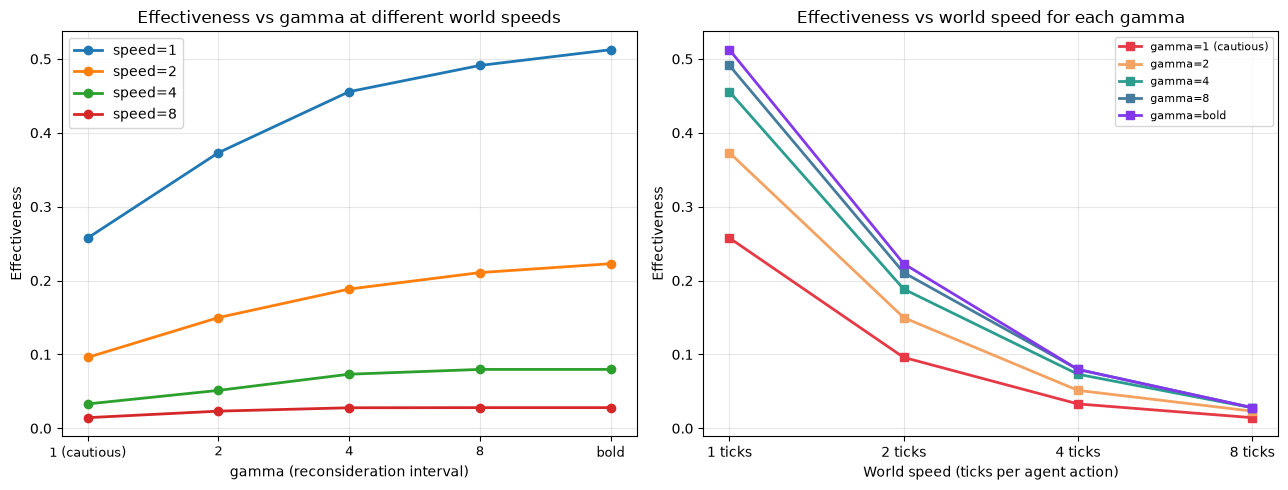

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ['#e63946', '#f4a261', '#2a9d8f', '#457b9d', '#8338ec']

# Left: effectiveness vs gamma
ax = axes[0]
x = np.arange(len(GAMMAS))
for sp in SPEEDS:
    y = [results[(g, sp)] for g in GAMMAS]
    ax.plot(x, y, marker='o', label=f'speed={sp}', linewidth=2)
ax.set_xticks(x)
ax.set_xticklabels(GAMMA_LABELS, fontsize=9)
ax.set_xlabel('gamma (reconsideration interval)')
ax.set_ylabel('Effectiveness')
ax.set_title('Effectiveness vs gamma at different world speeds')
ax.legend(); ax.grid(True, alpha=0.3)

# Right: effectiveness vs speed
ax2 = axes[1]
x2 = np.arange(len(SPEEDS))
for i, (g, lbl) in enumerate(zip(GAMMAS, GAMMA_LABELS)):
    y2 = [results[(g, sp)] for sp in SPEEDS]
    ax2.plot(x2, y2, marker='s', label=f'gamma={lbl}', linewidth=2, color=colors[i])
ax2.set_xticks(x2)
ax2.set_xticklabels([str(s)+' ticks' for s in SPEEDS])
ax2.set_xlabel('World speed (ticks per agent action)')
ax2.set_ylabel('Effectiveness')
ax2.set_title('Effectiveness vs world speed for each gamma')
ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Observations — Exercise 1

- At **low speed (1 tick/action)**, the world changes slowly; bold agents (large γ) dominate because they follow through on plans and spend little time deliberating.
- As **world speed increases**, holes appear and expire faster; cautious agents (small γ) re-deliberate frequently and adapt better.
- **Both extremes are suboptimal**: γ=1 wastes an agent time step re-deliberating when the world hasn't changed; bold γ chases a hole that may have expired during the pursuit.
- An **intermediate γ** maximises effectiveness at most speeds — this optimum falls as the world speeds up, confirming Kinny & Georgeff's result.

## Exercise 2 — Resource-Bounded Filter (Battery)

Battery capacity = 40. Loses 1 unit per move. Charger at (0, 0) restores it fully.

**Plan library:**
- `fill-hole`: applicable only if battery ≥ dist(agent→hole) + dist(hole→charger).
- `recharge`: always applicable.

**Filter:** commit to nearest affordable hole; otherwise head to charger.

Compare against a **battery-blind** agent that always chases the nearest hole.

In [5]:
CHARGER     = (0, 0)
BATTERY_CAP = 40

class BDIAgentBattery(BDIAgent):
    """Battery-aware BDI agent with resource-bounded filter."""
    def __init__(self, gamma=1, verbose=False):
        super().__init__(gamma=gamma, verbose=verbose)
        self.battery      = BATTERY_CAP
        self.recharging   = False
        self.steps_stranded = 0

    def filter(self, desires):
        # fill-hole precondition: battery covers trip + return to charger
        affordable = [h for h in desires
                      if manhattan(self.pos, h) + manhattan(h, CHARGER) <= self.battery]
        if affordable:
            self.recharging = False
            return min(affordable, key=lambda h: manhattan(self.pos, h))
        self.recharging = True
        return CHARGER  # recharge schema

    def step(self, world, ticks_per_action):
        for _ in range(ticks_per_action):
            world.tick()
        perc_holes, perc_pos = world.percept(self.pos)
        self.brf(perc_holes, perc_pos)

        if self.intention and self.intention != CHARGER and self.intention not in self.beliefs:
            self.events.append(('DROP', self.intention))
            self.intention = None; self.plan = []

        if self.intention is None or not self.plan:
            desires = self.options()
            self.intention = self.filter(desires)
            self.plan = astar(self.pos, self.intention)[1:] if self.intention else []
            self.since_replan = 0
        elif self.since_replan >= self.gamma:
            for _ in range(ticks_per_action):
                world.tick()
            perc_holes, _ = world.percept(self.pos)
            self.brf(perc_holes, self.pos)
            desires = self.options()
            self.intention = self.filter(desires)
            self.plan = astar(self.pos, self.intention)[1:] if self.intention else []
            self.since_replan = 0

        if self.plan:
            if self.battery <= 0:
                self.steps_stranded += 1; return
            self.pos     = self.plan.pop(0)
            self.battery -= 1
            self.since_replan += 1
            if self.pos == CHARGER:
                self.battery = BATTERY_CAP
                if self.recharging:
                    self.intention = None; self.plan = []
            elif world.fill(self.pos):
                self.events.append(('ACHIEVE', self.pos))
                self.intention = None; self.plan = []


class BDIAgentBlind(BDIAgent):
    """Battery-blind agent: always chases nearest hole."""
    def __init__(self, gamma=1, verbose=False):
        super().__init__(gamma=gamma, verbose=verbose)
        self.battery      = BATTERY_CAP
        self.steps_stranded = 0

    def step(self, world, ticks_per_action):
        for _ in range(ticks_per_action):
            world.tick()
        perc_holes, perc_pos = world.percept(self.pos)
        self.brf(perc_holes, perc_pos)
        if self.intention and self.intention not in self.beliefs:
            self.intention = None; self.plan = []
        if self.intention is None or not self.plan:
            desires = self.options()
            self.intention = self.filter(desires)
            self.plan = astar(self.pos, self.intention)[1:] if self.intention else []
        if self.plan:
            if self.battery <= 0:
                self.steps_stranded += 1; return
            self.pos     = self.plan.pop(0)
            self.battery -= 1
            if world.fill(self.pos):
                self.intention = None; self.plan = []


def run_battery(AgentClass, gamma=1, ticks_per_action=2, steps=600, seed=42):
    world = Tileworld(seed=seed)
    agent = AgentClass(gamma=gamma)
    for _ in range(steps):
        agent.step(world, ticks_per_action)
    return world.holes_filled, world.holes_appeared, agent.steps_stranded


SEEDS25 = list(range(25))
SPEED   = 2

aware = [run_battery(BDIAgentBattery, seed=s, ticks_per_action=SPEED) for s in SEEDS25]
blind = [run_battery(BDIAgentBlind,   seed=s, ticks_per_action=SPEED) for s in SEEDS25]

def mean_eff(res):
    return np.mean([f/a if a > 0 else 0 for f, a, _ in res])

print('=== Exercise 2: Battery-Aware BDI vs Battery-Blind ===')
print('Agent'.rjust(22) + 'Holes Filled'.rjust(14) + 'Effectiveness'.rjust(16) + 'Stranded Steps'.rjust(16))
print('-' * 70)
print('Battery-Aware (BDI)'.rjust(22) +
      f"{np.mean([r[0] for r in aware]):.1f}".rjust(14) +
      f"{mean_eff(aware):.3f}".rjust(16) +
      f"{np.mean([r[2] for r in aware]):.1f}".rjust(16))
print('Battery-Blind'.rjust(22) +
      f"{np.mean([r[0] for r in blind]):.1f}".rjust(14) +
      f"{mean_eff(blind):.3f}".rjust(16) +
      f"{np.mean([r[2] for r in blind]):.1f}".rjust(16))


=== Exercise 2: Battery-Aware BDI vs Battery-Blind ===
                 Agent  Holes Filled   Effectiveness  Stranded Steps
----------------------------------------------------------------------
   Battery-Aware (BDI)           4.6           0.055             0.0
         Battery-Blind           2.7           0.044           211.9


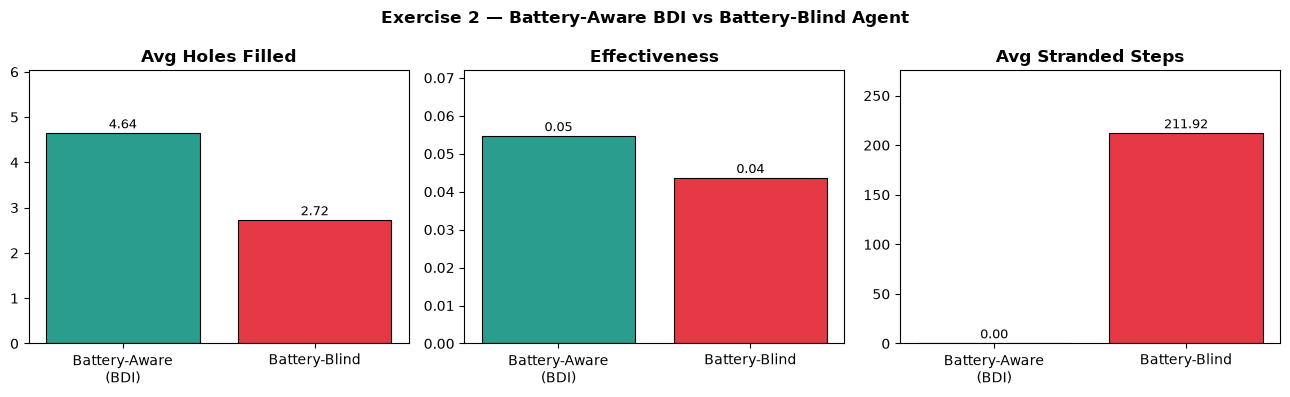

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
labels = ['Battery-Aware\n(BDI)', 'Battery-Blind']
cols = ['#2a9d8f', '#e63946']

data = [
    ([np.mean([r[0] for r in aware]), np.mean([r[0] for r in blind])], 'Avg Holes Filled'),
    ([mean_eff(aware), mean_eff(blind)], 'Effectiveness'),
    ([np.mean([r[2] for r in aware]), np.mean([r[2] for r in blind])], 'Avg Stranded Steps'),
]

for ax, (vals, title) in zip(axes, data):
    bars = ax.bar(labels, vals, color=cols, edgecolor='black', linewidth=0.8)
    ax.set_title(title, fontweight='bold')
    ax.set_ylim(0, max(vals) * 1.3 + 0.001)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01 * (max(vals) + 0.001),
                f'{v:.2f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Exercise 2 — Battery-Aware BDI vs Battery-Blind Agent', fontweight='bold')
plt.tight_layout()
plt.show()


### Observations — Exercise 2

- The **battery-aware BDI agent** fills more holes and has far fewer stranded steps because its **filter** checks feasibility before committing — only pursuing holes reachable given current battery.
- The **battery-blind agent** commits to unreachable holes; when the battery runs out it is stranded, wasting steps and missing filling opportunities.
- The fix belongs in the **filter** (deliberation step), **not the planner**: the filter decides *which goal to commit to*; the planner only computes *how* to reach an already-chosen goal. Battery is a precondition on commitment, not on path planning.